In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Задача 1. Равномерное распределение и два метода

Пусть $X_1,\ldots,X_n$ — выборка из равномерного распределения

$$
X_i\sim U(0,\theta),
$$

где $\theta>0$ — неизвестный параметр.

Для параметра $\theta$ предложены две оценки:

$$
\widehat\theta_1=2\overline X,
\qquad
\widehat\theta_2=X_{(n)},
$$

где $X_{(n)}=\max(X_1,\ldots,X_n)$.

1. Какая оценка получена методом моментов?
2. Какая оценка получена методом максимального правдоподобия?
3. Почему оценки различаются?


**Решение**


## Пункт 1. Метод моментов

Для $U(0,\theta)$

$$
\mathbb E[X]=\frac\theta2.
$$

Приравниваем к выборочному среднему:

$$
\frac\theta2=\overline X.
$$

Отсюда

$$
\boxed{\widehat\theta_{MM}=2\overline X}.
$$


## Пункт 2. Метод максимального правдоподобия

Плотность одного наблюдения:

$$
f(x;\theta)=
\begin{cases}
\frac1\theta, & 0\le x\le\theta,\\
0, & \text{иначе}.
\end{cases}
$$

Если $\theta<X_{(n)}$, то наблюдавшийся максимум вообще не мог появиться, поэтому

$$
L(\theta)=0.
$$

Для допустимых значений $\theta\ge X_{(n)}$ имеем

$$
L(\theta)=\frac1{\theta^n}.
$$

Эта величина уменьшается при росте $\theta$. Поэтому среди всех допустимых значений правдоподобие максимально при самом маленьком:

$$
\boxed{\widehat\theta_{MLE}=X_{(n)}}.
$$

Здесь максимум достигается **на границе**, поэтому уравнение $\ell'(\theta)=0$ нам не требуется.


# Задача 2. Смещение оценки для экспоненциального распределения

Пусть истинный параметр экспоненциального распределения равен

$$
\lambda=2.
$$

Для каждой выборки будем оценивать его по формуле

$$
\widehat\lambda=\frac1{\overline X}.
$$

1. Сгенерируйте 5000 выборок объёма $n=5$ и для каждой вычислите $\widehat\lambda$.
2. Найдите среднее полученных оценок.
3. Повторите эксперимент для $n=20$ и $n=100$.
4. Сравните среднее значение оценок с истинным $\lambda=2$.
5. Что происходит при увеличении размера выборки?


**Решение**


In [ ]:
lambda_true = 2
n_experiments = 5000
rng = np.random.default_rng(42)

for n in [5, 20, 100]:
    estimates = []

    for _ in range(n_experiments):
        sample = rng.exponential(scale=1 / lambda_true, size=n)
        estimates.append(1 / sample.mean())

    mean_estimate = np.mean(estimates)

    print(f"n = {n}")
    print(f"Средняя оценка: {mean_estimate:.3f}")
    print(f"Истинное значение: {lambda_true}")
    print(f"Разница: {mean_estimate - lambda_true:.3f}")
    print()


n = 5
Средняя оценка: 2.513
Истинное значение: 2
Разница: 0.513

n = 20
Средняя оценка: 2.101
Истинное значение: 2
Разница: 0.101

n = 100
Средняя оценка: 2.024
Истинное значение: 2
Разница: 0.024



**Вывод**

При небольшом $n$ среднее значение $\widehat\lambda$ оказывается выше истинного $\lambda=2$ — мы наблюдаем **смещение вверх**.

При увеличении размера выборки среднее значение оценок приближается к $2$, а смещение становится меньше.

Важно: моделирование показывает поведение оценки **экспериментально**, но само по себе не является строгим доказательством несмещённости или смещённости.


# Appendix. ML application

## Зачем ММП нужно в машинном обучении?

До сих пор мы говорили:

> есть неизвестный параметр распределения — нужно его оценить.

В машинном обучении происходит почти то же самое.

Есть модель с параметрами $\theta$, есть наблюдаемые данные, и нужно выбрать такие параметры, при которых эти данные наиболее правдоподобны:

$$
\widehat\theta
=
\arg\max_\theta L(\theta).
$$

То есть обучение многих моделей можно рассматривать как **задачу максимального правдоподобия**.

На практике обычно максимизируют не само правдоподобие, а логарифм:

$$
\widehat\theta
=
\arg\max_\theta \log L(\theta).
$$

Или, что то же самое, минимизируют **отрицательный логарифм правдоподобия**:

$$
\boxed{
\widehat\theta
=
\arg\min_\theta
\left[-\log L(\theta)\right]
}
$$

В машинном обучении выражение, которое минимизируется, обычно называют **функцией потерь — loss**.

Поэтому многие знакомые loss-функции возникают не случайно: они следуют из предположения о распределении данных.

## Примеры

**Линейная регрессия**

Если считаем ошибки нормальными,

$$
Y_i\mid X_i\sim\mathcal N(\widehat Y_i,\sigma^2),
$$

то ММП приводит к минимизации суммы квадратов ошибок:

$$
\sum_i(Y_i-\widehat Y_i)^2.
$$

Отсюда появляется **MSE**.

**Логистическая регрессия**

Если

$$
Y_i\sim\operatorname{Bernoulli}(p_i),
$$

то максимизация правдоподобия приводит к **log loss / binary cross-entropy**.

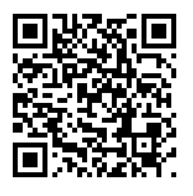